# Pipeline Gardenia | Etapa 4: Data Warehouse (esquema estrela)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anlbp/Projeto-Gardenia-unifeob/blob/main/recursos/dados/notebook_dados_nao_filtrados/04_data_warehouse.ipynb)

**Lê:** `trusted_clientes_N.csv`, `trusted_produtos_N.csv`, `trusted_compras_N.csv`, gerados pelo notebook 03 (por padrão em `{DRIVE_PASTA}/saida`).
**Gera:** `dim_cliente`, `dim_produto`, `dim_data` e `fato_vendas`, em CSV e em um banco SQLite (`dw_gardenia.sqlite`), por padrão em `{DRIVE_PASTA}/dw`. O notebook de OLAP lê de lá.

> Antes de rodar este notebook, rode o 03. Ele grava os dados limpos no Drive.

## Modelo

```
                    dim_data
                       |
dim_cliente ---- fato_vendas ---- dim_produto
```

| Tabela | Grão (uma linha por...) | Chave |
|---|---|---|
| `fato_vendas` | compra | `id_compra` (`lote_id`) |
| `dim_cliente` | cliente | `id_cliente` (`lote_id`) |
| `dim_produto` | produto | `id_produto` (`lote_id`) |
| `dim_data` | dia | `id_data` (`AAAAMMDD`) |

As chaves são **compostas** (`lote` + `id`) porque o gerador reinicia os ids a cada ciclo. Sem o lote, o cliente 1 do ciclo 1 se confundiria com o cliente 1 do ciclo 2.

Decisões de modelagem:

- **Medidas** da fato: `quantidade`, `valor_total`, `desconto`, `valor_liquido` (`valor_total - desconto`) e `satisfacao`.
- **`status`** fica na fato como dimensão degenerada (só 5 valores, sem atributos próprios).
- **Dados pessoais** (`email`, `telefone`, `cpf`) **não entram** no DW. A análise não precisa deles e isso reduz o risco com a LGPD.

## 1. Configuração e carga

In [7]:
# ============================ CONFIGURAÇÃO ============================
FONTE_TRUSTED = "drive"     # "drive" | "github" | "upload" | "local"
LOTE = "1"                  # mesmo lote usado no notebook 03

DRIVE_PASTA = "/content/drive/MyDrive/gardenia"   # o 03 grava em {DRIVE_PASTA}/saida

# --- usado quando FONTE_TRUSTED == "github" (arquivos trusted versionados no repositório) ---
GITHUB_USUARIO = "Anlbp"
GITHUB_REPO    = "Projeto-Gardenia-unifeob"
GITHUB_BRANCH  = "main"
PASTA_GITHUB   = "recursos/dados/trusted"

# --- usado quando FONTE_TRUSTED == "local" ---
PASTA_LOCAL = "saida"

# --- saída ---
SALVAR_NO_DRIVE = True      # True: grava em {DRIVE_PASTA}/dw
SAIDA = "dw"                # pasta usada quando SALVAR_NO_DRIVE = False
# =======================================================================

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import io
import os
import sqlite3
import urllib.error
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

TABELAS = ["clientes", "produtos", "compras"]
nomes_arquivo = {t: f"trusted_{t}_{LOTE}.csv" for t in TABELAS}

if FONTE_TRUSTED == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    caminhos = {t: f"{DRIVE_PASTA}/saida/{a}" for t, a in nomes_arquivo.items()}

elif FONTE_TRUSTED == "github":
    branch = GITHUB_BRANCH.removeprefix("tree/")
    base = f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{GITHUB_REPO}/{branch}/{PASTA_GITHUB}"
    caminhos = {t: f"{base}/{a}" for t, a in nomes_arquivo.items()}

elif FONTE_TRUSTED == "upload":
    from google.colab import files
    print("Selecione os 3 arquivos trusted_*.csv gerados pelo notebook 03")
    files.upload()
    caminhos = dict(nomes_arquivo)

elif FONTE_TRUSTED == "local":
    caminhos = {t: f"{PASTA_LOCAL}/{a}" for t, a in nomes_arquivo.items()}

else:
    raise ValueError('FONTE_TRUSTED deve ser "drive", "github", "upload" ou "local".')

for t, c in caminhos.items():
    print(f"{t:10s} <- {c}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
clientes   <- /content/drive/MyDrive/gardenia/saida/trusted_clientes_1.csv
produtos   <- /content/drive/MyDrive/gardenia/saida/trusted_produtos_1.csv
compras    <- /content/drive/MyDrive/gardenia/saida/trusted_compras_1.csv


In [10]:
import os
pasta = "/content/drive/MyDrive/gardenia"
print("gardenia existe:", os.path.exists(pasta))
for raiz, _, arquivos in os.walk(pasta):
    print(raiz, arquivos)

gardenia existe: True
/content/drive/MyDrive/gardenia []
/content/drive/MyDrive/gardenia/saida ['trusted_compras_1.csv', 'trusted_produtos_1.csv', 'trusted_clientes_1.csv', 'quarentena_produtos_1.csv', 'relatorio_qualidade_1.csv', 'quarentena_compras_1.csv']


In [11]:
def ler_trusted(origem):
    try:
        if origem.startswith("http"):
            with urllib.request.urlopen(origem) as resp:
                texto = resp.read().decode("utf-8")
            return pd.read_csv(io.StringIO(texto))
        return pd.read_csv(origem)
    except (FileNotFoundError, urllib.error.HTTPError):
        raise FileNotFoundError(
            f"Não encontrei {origem}.\n"
            "Rode antes o notebook 03 (limpeza) com o mesmo LOTE e SALVAR_NO_DRIVE = True. "
            "Se os arquivos estão em outro lugar, ajuste FONTE_TRUSTED e as pastas na configuração."
        ) from None


clientes = ler_trusted(caminhos["clientes"])
produtos = ler_trusted(caminhos["produtos"])
compras = ler_trusted(caminhos["compras"])

# datas voltam como texto do CSV
clientes["data_nascimento"] = pd.to_datetime(clientes["data_nascimento"], errors="coerce")
clientes["data_cadastro"] = pd.to_datetime(clientes["data_cadastro"], errors="coerce")
produtos["data_cadastro"] = pd.to_datetime(produtos["data_cadastro"], errors="coerce")
compras["data_compra"] = pd.to_datetime(compras["data_compra"], errors="coerce")

for nome, df in [("clientes", clientes), ("produtos", produtos), ("compras", compras)]:
    assert "inconsistente" not in df.columns, f"{nome}: a coluna 'inconsistente' deveria ter saído no notebook 03"
    print(f"{nome:10s} {df.shape}")

clientes   (5000, 9)
produtos   (2305, 8)
compras    (1184, 9)


## 2. Dimensões

Cada dimensão tem a chave composta `lote_id` e atributos descritivos úteis para o OLAP (faixas de idade e de preço, calendário completo).

In [12]:
# ---- dim_cliente ----
dim_cliente = pd.DataFrame({
    "id_cliente": LOTE + "_" + clientes["id"].astype(str),
    "nome": clientes["nome"],
    "idade": clientes["idade"].astype("Int64"),
    "data_nascimento": clientes["data_nascimento"],
    "data_cadastro": clientes["data_cadastro"],
    "cadastro_incompleto": clientes["cadastro_incompleto"],
})
faixa = pd.cut(
    dim_cliente["idade"].astype(float),
    bins=[17, 24, 34, 44, 54, 64, 200],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
)
dim_cliente["faixa_etaria"] = faixa.astype(object).where(faixa.notna(), "Não informada")

# ---- dim_produto ----
dim_produto = pd.DataFrame({
    "id_produto": LOTE + "_" + produtos["id"].astype(str),
    "nome": produtos["nome"],
    "categoria": produtos["categoria"],
    "preco": produtos["preco"],
    "estoque": produtos["estoque"],
    "peso": produtos["peso"],
    "satisfacao_media": produtos["satisfacao_media"],
    "data_cadastro": produtos["data_cadastro"],
})
faixa = pd.cut(
    dim_produto["preco"],
    bins=[0, 100, 300, 600, np.inf],
    labels=["Até R$ 100", "R$ 100 a 300", "R$ 300 a 600", "Acima de R$ 600"],
)
dim_produto["faixa_preco"] = faixa.astype(object)

# ---- dim_data: um dia por linha, sem buracos entre a primeira e a última compra ----
MESES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho",
         "julho", "agosto", "setembro", "outubro", "novembro", "dezembro"]
DIAS = ["segunda", "terça", "quarta", "quinta", "sexta", "sábado", "domingo"]

dias = pd.date_range(compras["data_compra"].min().normalize(), compras["data_compra"].max().normalize(), freq="D")
dim_data = pd.DataFrame({"data": dias})
dim_data["id_data"] = dim_data["data"].dt.strftime("%Y%m%d").astype(int)
dim_data["dia"] = dim_data["data"].dt.day
dim_data["mes"] = dim_data["data"].dt.month
dim_data["nome_mes"] = dim_data["mes"].map(lambda m: MESES[m - 1])
dim_data["trimestre"] = dim_data["data"].dt.quarter
dim_data["ano"] = dim_data["data"].dt.year
dim_data["ano_mes"] = dim_data["data"].dt.strftime("%Y-%m")
dim_data["dia_semana"] = dim_data["data"].dt.dayofweek.map(lambda d: DIAS[d])
dim_data["fim_de_semana"] = dim_data["data"].dt.dayofweek >= 5
dim_data = dim_data[["id_data", "data", "dia", "mes", "nome_mes", "trimestre", "ano", "ano_mes",
                     "dia_semana", "fim_de_semana"]]

for nome, df in [("dim_cliente", dim_cliente), ("dim_produto", dim_produto), ("dim_data", dim_data)]:
    print(f"{nome:12s} {df.shape}")
dim_data.head()

dim_cliente  (5000, 7)
dim_produto  (2305, 9)
dim_data     (366, 10)


,id_data,data,dia,mes,nome_mes,trimestre,ano,ano_mes,dia_semana,fim_de_semana
0,20251009,2025-10-09,9,10,outubro,4,2025,2025-10,quinta,False
1,20251010,2025-10-10,10,10,outubro,4,2025,2025-10,sexta,False
2,20251011,2025-10-11,11,10,outubro,4,2025,2025-10,sábado,True
3,20251012,2025-10-12,12,10,outubro,4,2025,2025-10,domingo,True
4,20251013,2025-10-13,13,10,outubro,4,2025,2025-10,segunda,False


## 3. Tabela fato

Uma linha por compra. As chaves estrangeiras usam o mesmo formato `lote_id` das dimensões.

In [13]:
fato_vendas = pd.DataFrame({
    "id_compra": LOTE + "_" + compras["id"].astype(str),
    "id_cliente": LOTE + "_" + compras["cliente_id"].astype(str),
    "id_produto": LOTE + "_" + compras["produto_id"].astype(str),
    "id_data": compras["data_compra"].dt.strftime("%Y%m%d").astype(int),
    "status": compras["status"],
    "quantidade": compras["quantidade"],
    "valor_total": compras["valor_total"],
    "desconto": compras["desconto"],
    "valor_liquido": (compras["valor_total"] - compras["desconto"]).round(2),
    "satisfacao": compras["satisfacao"].astype("Int64"),
})
print(fato_vendas.shape)
fato_vendas.head()

(1184, 10)


,id_compra,id_cliente,id_produto,id_data,status,quantidade,valor_total,desconto,valor_liquido,satisfacao
0,1_15,1_4487,1_3038,20260909,entregue,8,3475.74,448.70,3027.04,2
1,1_16,1_3240,1_992,20260523,cancelado,8,474.91,33.96,440.95,1
2,1_21,1_2478,1_1409,20260529,enviado,9,3699.06,973.60,2725.46,4
3,1_26,1_3167,1_1603,20260806,pendente,4,2455.84,561.57,1894.27,<NA>
4,1_28,1_2381,1_4856,20260213,enviado,1,4140.57,411.00,3729.57,3


## 4. Verificações de integridade

O DW só é confiável se toda chave da fato existir na dimensão correspondente e se nenhuma chave se repetir.

In [14]:
# chaves primárias únicas
assert dim_cliente["id_cliente"].is_unique, "dim_cliente com chaves duplicadas"
assert dim_produto["id_produto"].is_unique, "dim_produto com chaves duplicadas"
assert dim_data["id_data"].is_unique, "dim_data com chaves duplicadas"
assert fato_vendas["id_compra"].is_unique, "fato_vendas com chaves duplicadas"

# chaves estrangeiras da fato existem nas dimensões
assert fato_vendas["id_cliente"].isin(dim_cliente["id_cliente"]).all(), "fato com cliente inexistente"
assert fato_vendas["id_produto"].isin(dim_produto["id_produto"]).all(), "fato com produto inexistente"
assert fato_vendas["id_data"].isin(dim_data["id_data"]).all(), "fato com data inexistente"

# nenhuma compra se perdeu e as medidas fecham com a trusted
assert len(fato_vendas) == len(compras), "linhas perdidas na fato"
assert np.isclose(fato_vendas["valor_total"].sum(), compras["valor_total"].sum())
assert (fato_vendas["valor_liquido"] > 0).all(), "valor_liquido <= 0 (a limpeza deveria ter barrado)"

print("Todas as verificações passaram.")
print(f"Receita bruta:   R$ {fato_vendas['valor_total'].sum():,.2f}")
print(f"Descontos:       R$ {fato_vendas['desconto'].sum():,.2f}")
print(f"Receita líquida: R$ {fato_vendas['valor_liquido'].sum():,.2f}")

Todas as verificações passaram.
Receita bruta:   R$ 2,947,197.51
Descontos:       R$ 441,119.71
Receita líquida: R$ 2,506,077.80


## 5. Teste do esquema estrela

Uma consulta SQL juntando a fato com duas dimensões mostra que o modelo funciona. O DW é gravado em SQLite, que já vem no Python e é lido pelo notebook de OLAP.

In [15]:
con = sqlite3.connect(":memory:")
for nome, df in {"dim_cliente": dim_cliente, "dim_produto": dim_produto,
                 "dim_data": dim_data, "fato_vendas": fato_vendas}.items():
    df.to_sql(nome, con, index=False)

consulta = '''
SELECT p.categoria,
       d.ano,
       COUNT(*)                       AS compras,
       ROUND(SUM(f.valor_liquido), 2) AS receita_liquida
FROM fato_vendas f
JOIN dim_produto p ON p.id_produto = f.id_produto
JOIN dim_data    d ON d.id_data    = f.id_data
GROUP BY p.categoria, d.ano
ORDER BY receita_liquida DESC
'''
resultado = pd.read_sql(consulta, con)
con.close()
resultado.head(10)

,categoria,ano,compras,receita_liquida
0,Roupas,2026,152,320138.62
1,Esportes,2026,145,316154.31
2,Livros,2026,131,266379.52
3,Brinquedos,2026,130,265856.74
4,Casa,2026,126,261489.67
5,Eletrônicos,2026,109,234536.91
6,Alimentos,2026,115,227396.76
7,Livros,2025,52,123151.41
8,Roupas,2025,45,99912.85
9,Alimentos,2025,40,98621.06


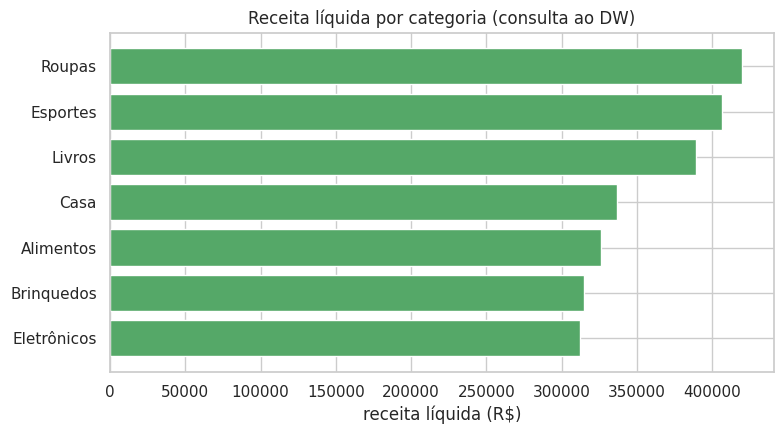

Categoria com maior receita líquida: Roupas (R$ 420,051.47, 16.8% do total).


In [16]:
por_categoria = resultado.groupby("categoria")["receita_liquida"].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(por_categoria.index, por_categoria.values, color="#55A868")
ax.set_title("Receita líquida por categoria (consulta ao DW)")
ax.set_xlabel("receita líquida (R$)")
plt.tight_layout()
plt.show()

top = por_categoria.index[-1]
print(f"Categoria com maior receita líquida: {top} (R$ {por_categoria.iloc[-1]:,.2f}, "
      f"{100 * por_categoria.iloc[-1] / por_categoria.sum():.1f}% do total).")

## 6. Perfil do DW

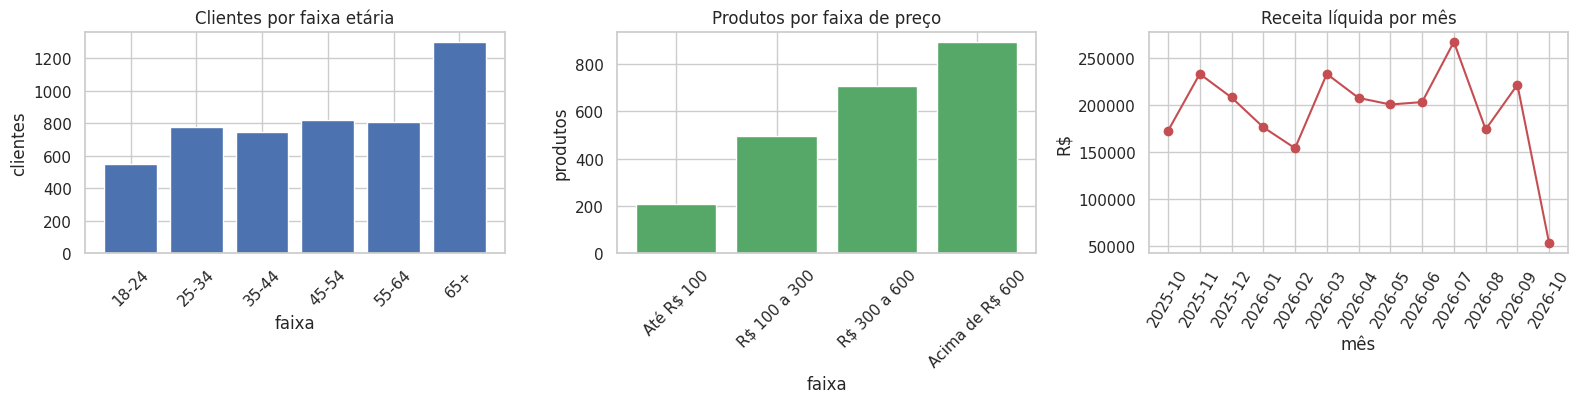

Faixa etária mais comum: 65+.
Faixa de preço mais comum: Acima de R$ 600.
Mês com maior receita líquida: 2026-07 (R$ 267,439.28).
Cobertura do calendário: 2025-10-09 a 2026-10-09 (366 dias).


In [17]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.2))

ordem = dim_cliente["faixa_etaria"].value_counts().reindex(
    ["18-24", "25-34", "35-44", "45-54", "55-64", "65+", "Não informada"]).dropna()
eixos[0].bar(ordem.index, ordem.values, color="#4C72B0")
eixos[0].set(title="Clientes por faixa etária", xlabel="faixa", ylabel="clientes")
eixos[0].tick_params(axis="x", rotation=45)

ordem = dim_produto["faixa_preco"].value_counts().reindex(
    ["Até R$ 100", "R$ 100 a 300", "R$ 300 a 600", "Acima de R$ 600"]).dropna()
eixos[1].bar(ordem.index, ordem.values, color="#55A868")
eixos[1].set(title="Produtos por faixa de preço", xlabel="faixa", ylabel="produtos")
eixos[1].tick_params(axis="x", rotation=45)

mensal = fato_vendas.merge(dim_data[["id_data", "ano_mes"]], on="id_data").groupby("ano_mes")["valor_liquido"].sum()
eixos[2].plot(mensal.index, mensal.values, marker="o", color="#C44E52")
eixos[2].set(title="Receita líquida por mês", xlabel="mês", ylabel="R$")
eixos[2].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

print(f"Faixa etária mais comum: {dim_cliente['faixa_etaria'].value_counts().idxmax()}.")
print(f"Faixa de preço mais comum: {dim_produto['faixa_preco'].value_counts().idxmax()}.")
print(f"Mês com maior receita líquida: {mensal.idxmax()} (R$ {mensal.max():,.2f}).")
print(f"Cobertura do calendário: {dim_data['data'].min().date()} a {dim_data['data'].max().date()} ({len(dim_data)} dias).")

## 7. Salvar o DW

Grava as quatro tabelas em CSV e em um único arquivo SQLite. O notebook de OLAP pode ler qualquer um dos dois.

In [18]:
if SALVAR_NO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        SAIDA = f"{DRIVE_PASTA}/dw"
    except ImportError:
        print("Fora do Colab: salvando na pasta local", SAIDA)
os.makedirs(SAIDA, exist_ok=True)

tabelas_dw = {"dim_cliente": dim_cliente, "dim_produto": dim_produto,
              "dim_data": dim_data, "fato_vendas": fato_vendas}

for nome, df in tabelas_dw.items():
    df.to_csv(f"{SAIDA}/{nome}_{LOTE}.csv", index=False)

caminho_db = f"{SAIDA}/dw_gardenia_{LOTE}.sqlite"
if os.path.exists(caminho_db):
    os.remove(caminho_db)
con = sqlite3.connect(caminho_db)
for nome, df in tabelas_dw.items():
    df.to_sql(nome, con, index=False)
con.close()

for nome, df in tabelas_dw.items():
    print(f"{SAIDA}/{nome}_{LOTE}.csv  {len(df):>6} linhas")
print(f"{caminho_db}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/gardenia/dw/dim_cliente_1.csv    5000 linhas
/content/drive/MyDrive/gardenia/dw/dim_produto_1.csv    2305 linhas
/content/drive/MyDrive/gardenia/dw/dim_data_1.csv     366 linhas
/content/drive/MyDrive/gardenia/dw/fato_vendas_1.csv    1184 linhas
/content/drive/MyDrive/gardenia/dw/dw_gardenia_1.sqlite


## Próximos passos

**Etapa 5: OLAP.** Ler o DW (`dw_gardenia_N.sqlite` ou os `dim_*`/`fato_vendas` em CSV) e demonstrar roll-up, drill-down, slice e dice.

Checklist antes do commit:

- [ ] o notebook 03 foi rodado antes, com o mesmo `LOTE`;
- [ ] as verificações de integridade da seção 4 passam;
- [ ] `email`, `telefone` e `cpf` não aparecem em nenhuma tabela do DW;
- [ ] os gráficos têm título, eixos rotulados e uma frase de interpretação.